# DA Project (Supply Chain Analysis)

Members Involved in this project:
- Aaron C Abraham
- Dhanshree Varshini
- Alphin Issac Varghese

In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import gaussian_kde


pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

In [52]:
data:pd.DataFrame = pd.read_csv('/Users/alphin/Documents/Semester 5/DA Project/Suppy_Chain_Shipment_Data.csv')

In [53]:
data

,id,project code,pq #,po / so #,asn/dn #,country,managed by,fulfill via,vendor inco term,shipment mode,pq first sent to client date,po sent to vendor date,scheduled delivery date,delivered to client date,delivery recorded date,product group,sub classification,vendor,item description,molecule/test type,brand,dosage,dosage form,unit of measure (per pack),line item quantity,line item value,pack price,unit price,manufacturing site,first line designation,weight (kilograms),freight cost (usd),line item insurance (usd)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,2-Jun-06,2-Jun-06,2-Jun-06,HRDT,HIV test,RANBAXY Fine Chemicals LTD.,"HIV, Reveal G3 Rapid HIV-1 Antibody Test, 30 Tests","HIV, Reveal G3 Rapid HIV-1 Antibody Test",Reveal,NaN,Test kit,30,19,551.00,29.00,0.97,Ranbaxy Fine Chemicals LTD,True,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,14-Nov-06,14-Nov-06,14-Nov-06,ARV,Pediatric,Aurobindo Pharma Limited,"Nevirapine 10mg/ml, oral suspension, Bottle, 240 ml",Nevirapine,Generic,10mg/ml,Oral suspension,240,1000,6200.00,6.20,0.03,"Aurobindo Unit III, India",True,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,Pre-PQ Process,Date Not Captured,27-Aug-06,27-Aug-06,27-Aug-06,HRDT,HIV test,Abbott GmbH & Co. KG,"HIV 1/2, Determine Complete HIV Kit, 100 Tests","HIV 1/2, Determine Complete HIV Kit",Determine,NaN,Test kit,100,500,40000.00,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,True,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,1-Sep-06,1-Sep-06,1-Sep-06,ARV,Adult,SUN PHARMACEUTICAL INDUSTRIES LTD (RANBAXY LABORATORIES LIMITED),"Lamivudine 150mg, tablets, 60 Tabs",Lamivudine,Generic,150mg,Tablet,60,31920,127360.80,3.99,0.07,"Ranbaxy, Paonta Shahib, India",True,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,11-Aug-06,11-Aug-06,11-Aug-06,ARV,Adult,Aurobindo Pharma Limited,"Stavudine 30mg, capsules, 60 Caps",Stavudine,Generic,30mg,Capsule,60,38000,121600.00,3.20,0.05,"Aurobindo Unit III, India",True,7590,45450.08,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10319,86818,103-ZW-T30,FPQ-15197,SO-50020,DN-4307,Zimbabwe,PMO - US,From RDC,N/A - From RDC,Truck,10/16/2014,N/A - From RDC,31-Jul-15,15-Jul-15,20-Jul-15,ARV,Pediatric,SCMS from RDC,"Lamivudine/Nevirapine/Zidovudine 30/50/60mg, dispersible tablets, 60 Tabs",Lamivudine/Nevirapine/Zidovudine,Generic,30/50/60mg,Chewable/dispersible tablet - FDC,60,166571,599655.60,3.60,0.06,"Mylan, H-12 & H-13, India",False,See DN-4307 (ID#:83920),See DN-4307 (ID#:83920),705.79
10320,86819,104-CI-T30,FPQ-15259,SO-50102,DN-4313,Côte d'Ivoire,PMO - US,From RDC,N/A - From RDC,Truck,10/24/2014,N/A - From RDC,31-Jul-15,6-Aug-15,7-Aug-15,ARV,Adult,SCMS from RDC,"Lamivudine/Zidovudine 150/300mg, tablets, 60 Tabs",Lamivudine/Zidovudine,Generic,150/300mg,Tablet - FDC,60,21072,137389.44,6.52,0.11,Hetero Unit III Hyderabad IN,False,See DN-4313 (ID#:83921),See DN-4313 (ID#:83921),161.71
10321,86821,110-ZM-T30,FPQ-14784,SO-49600,DN-4316,Zambia,PMO - US,From RDC,N/A - From RDC,Truck,8/12/2014,N/A - From RDC,31-Aug-15,25-Aug-15,3-Sep-15,ARV,Adult,SCMS from RDC,"Efavirenz/Lamivudine/Tenofovir Disoproxil Fumarate 600/300/300mg, tablets, 30 Tabs",Efavirenz/Lamivudine/Tenofovir Disoproxil Fumarate,Generic,600/300/300mg,Tablet - FDC,30,514526,5140114.74,9.99,0.33,Cipla Ltd A-42 MIDC Mahar. IN,False,Weight Captured Separately,Freight Included in Commodity Cost,5284.04
10322,86822,200-ZW-T30,FPQ-16523,SO-51680,DN-4334,Zimbabwe,PMO - US,From RDC,N/A - From RDC,Truck,7/1/2015,N/A - From RDC,9-Sep-15,4-Aug-15,11-Aug-15,ARV,Adult,SCMS from RDC,"Lamivudine/Zidovu

# Manufacturing Sites and Shipment Delivery Sites

(<Figure size 1400x800 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

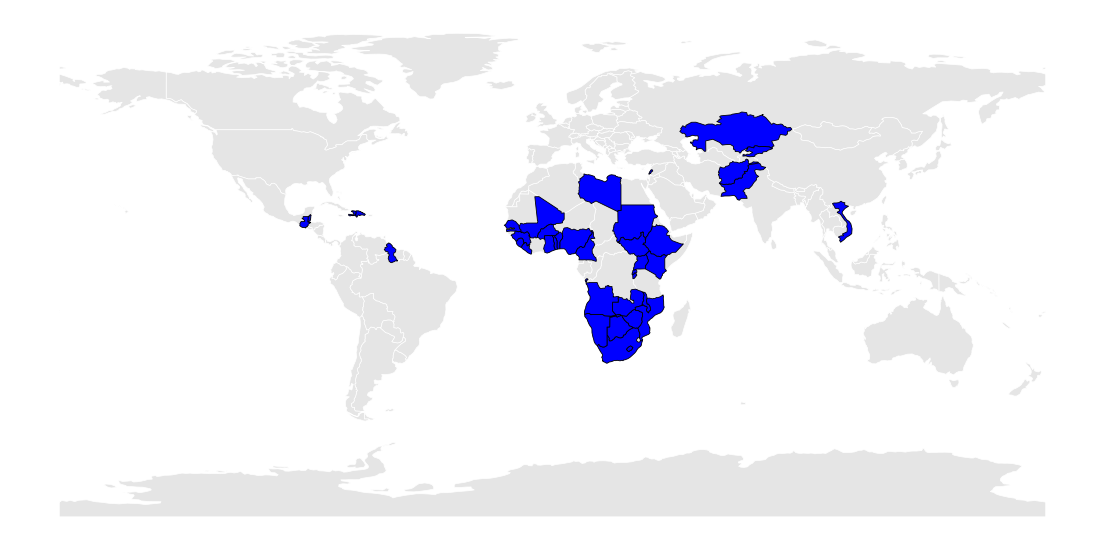

In [3]:
import geopandas as gpd
import matplotlib.pyplot as plt

def single_highlight_countries(countries, color="red"):
    # Load world boundaries
    url = "https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_countries.zip"

    world = gpd.read_file(url)

    # Find selected countries
    selected = world[world["ADMIN"].isin(countries)]

    # Plot
    fig, ax = plt.subplots(figsize=(14, 8))

    world.plot(
        ax=ax,
        color="#E5E5E5",
        edgecolor="white",
        linewidth=0.5
    )

    selected.plot(
        ax=ax,
        color=color,
        edgecolor="black",
        linewidth=0.6
    )

    ax.set_axis_off()

    return fig, ax

# Example
single_highlight_countries(data['country'].unique(), color="blue")

In [4]:
def double_highlight_countries(
    countries_1,
    countries_2,
    label_1="Group 1",
    label_2="Group 2",
    label_common="Common",
    color_1="#E63946",
    color_2="#457B9D",
    color_common="#F4A261"
):
    # Convert to sets
    countries_1 = set(countries_1)
    countries_2 = set(countries_2)

    # Separate the three categories
    common = countries_1 & countries_2
    only_1 = countries_1 - countries_2
    only_2 = countries_2 - countries_1

    # Load world map
    world = gpd.read_file("https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_countries.zip")

    # Plot base map
    fig, ax = plt.subplots(figsize=(16, 9))

    world.plot(
        ax=ax,
        color="#EAEAEA",
        edgecolor="white",
        linewidth=0.5
    )

    # Plot each category
    world[world["ADMIN"].isin(only_1)].plot(
        ax=ax,
        color=color_1,
        edgecolor="black",
        linewidth=0.6
    )

    world[world["ADMIN"].isin(only_2)].plot(
        ax=ax,
        color=color_2,
        edgecolor="black",
        linewidth=0.6
    )

    world[world["ADMIN"].isin(common)].plot(
        ax=ax,
        color=color_common,
        edgecolor="black",
        linewidth=0.6
    )

    # Legend
    legend_elements = [
        Patch(facecolor=color_1, label=label_1),
        Patch(facecolor=color_2, label=label_2),
        Patch(facecolor=color_common, label=label_common)
    ]

    ax.legend(
        handles=legend_elements,
        loc="lower left",
        frameon=True,
        fontsize=11
    )

    ax.set_axis_off()
    plt.tight_layout()
    plt.show()


In [5]:
from collections import Counter

country_counts = Counter({
    "India": 30,
    "United States of America": 17,
    "United Kingdom": 7,
    "Germany": 4,
    "Japan": 3,
    "Canada": 3,
    "South Africa": 3,
    "China": 3,
    "Italy": 3,
    "Cyprus": 3,
    "France": 2,
    "Switzerland": 2,
    "Spain": 2,
    "Australia": 1,
    "Ireland": 1,
    "Thailand": 1,
    "South Korea": 1,
    "Netherlands": 1,
    "Greece": 1,
    "Norway": 1,
    "Poland": 1
})

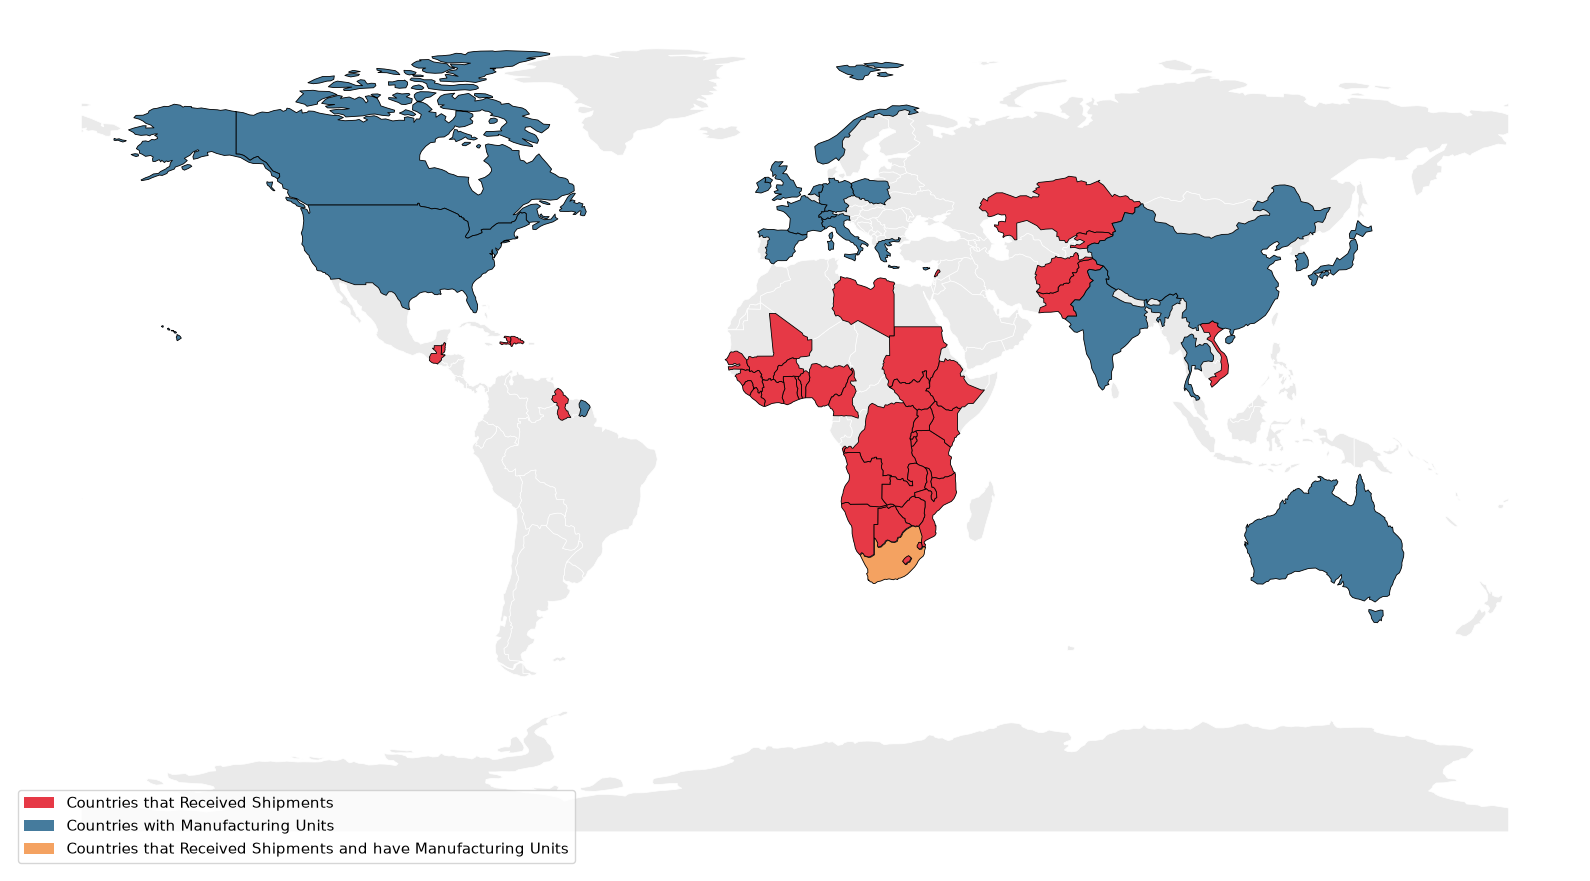

In [6]:
double_highlight_countries(
    countries_1 = data['country'].unique().tolist() + ['United Republic of Tanzania', 'Democratic Republic of the Congo', 'eSwatini', 'Ivory Coast'],
    countries_2 = country_counts.keys(),
    label_1 = "Countries that Received Shipments",
    label_2 = "Countries with Manufacturing Units",
    color_1 = "#E63946",
    color_2 = "#457B9D",
    label_common = "Countries that Received Shipments and have Manufacturing Units",
    color_common = "#F4A261"
)

# uggggg

In [7]:
temp = data[data["shipment mode"].isna() == True]

In [8]:
temp.describe(include="all")

,id,project code,pq #,po / so #,asn/dn #,country,managed by,fulfill via,vendor inco term,shipment mode,pq first sent to client date,po sent to vendor date,scheduled delivery date,delivered to client date,delivery recorded date,product group,sub classification,vendor,item description,molecule/test type,brand,dosage,dosage form,unit of measure (per pack),line item quantity,line item value,pack price,unit price,manufacturing site,first line designation,weight (kilograms),freight cost (usd),line item insurance (usd)
count,360.000000,360,360,360,360,360,360,360,360,0,360,360,360,360,360,360,360,360,360,360,360,309,360,360.000000,360.000000,3.600000e+02,360.000000,360.000000,360,360,360,360,254.000000
unique,NaN,15,1,220,226,12,1,2,5,0,1,8,127,130,129,3,5,7,68,35,28,30,11,NaN,NaN,NaN,NaN,NaN,36,2,259,261,NaN
top,NaN,110-ZM-T01,Pre-PQ Process,SCMS-16600,ASN-1520,Côte d'Ivoire,PMO - US,From RDC,N/A - From RDC,NaN,Pre-PQ Process,N/A - From RDC,21-Jan-08,4-Jan-08,4-Jan-08,ARV,Adult,SCMS from RDC,"Efavirenz 600mg, tablets, 30 Tabs",Efavirenz,Generic,600mg,Tablet,NaN,NaN,NaN,NaN,NaN,"Aurobindo Unit III, India",True,Weight Captured Separately,Freight Included in Commodity Cost,NaN
freq,NaN,99,360,18,16,113,360,312,312,NaN,360,312,20,16,16,309,239,312,42,62,213,44,126,NaN,NaN,NaN,NaN,NaN,141,226,47,49,NaN
mean,10683.311111,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,93.633333,10571.941667,1.121277e+05,26.780667,1.204667,NaN,NaN,NaN,NaN,196.738898
std,2571.053752,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,80.095236,18499.743518,1.983279e+05,42.496382,12.740643,NaN,NaN,NaN,NaN,346.458321
min,69.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,2.000000,1.520000e+00,0.010000,0.000000,NaN,NaN,NaN,NaN,0.000000
25%,10812.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.000000,484.250000,6.380000e+03,6.722500,0.100000,NaN,NaN,NaN,NaN,8.200000
50%,11373.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60.000000,1956.500000,3.144431e+04,16.125000,0.180000,NaN,NaN,NaN,NaN,46.220000
75%,12051.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.000000,10000.000000,1.205830e+05,35.275000,0.540000,NaN,NaN,NaN,NaN,209.855000


(<Figure size 1400x800 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

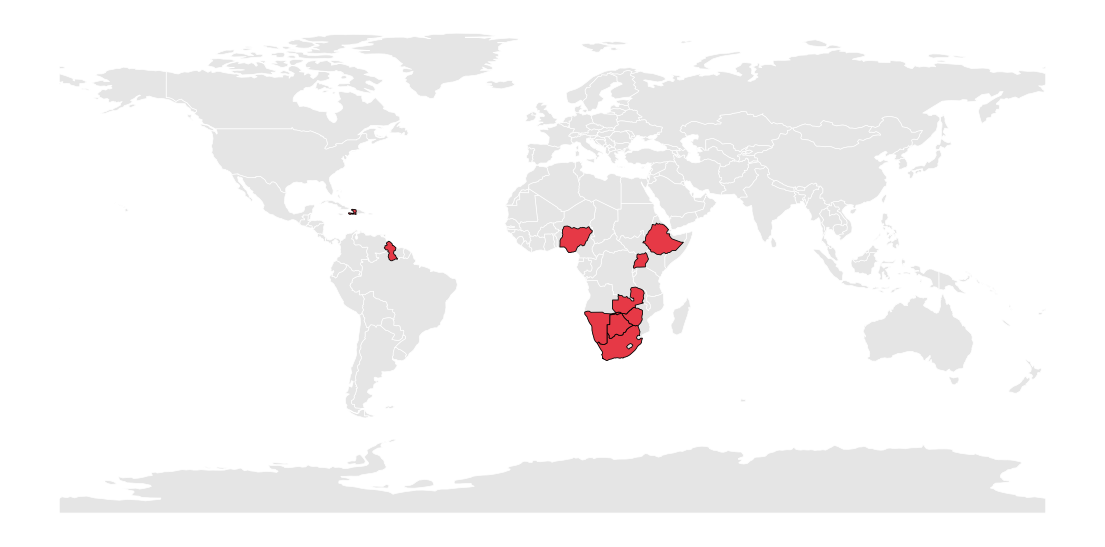

In [9]:
single_highlight_countries(
    countries = temp['country'].unique(),
    color = "#E63946"
)

In [10]:
data[data['project code'].isin(temp['project code'].unique())]

,id,project code,pq #,po / so #,asn/dn #,country,managed by,fulfill via,vendor inco term,shipment mode,pq first sent to client date,po sent to vendor date,scheduled delivery date,delivered to client date,delivery recorded date,product group,sub classification,vendor,item description,molecule/test type,brand,dosage,dosage form,unit of measure (per pack),line item quantity,line item value,pack price,unit price,manufacturing site,first line designation,weight (kilograms),freight cost (usd),line item insurance (usd)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,2-Jun-06,2-Jun-06,2-Jun-06,HRDT,HIV test,RANBAXY Fine Chemicals LTD.,"HIV, Reveal G3 Rapid HIV-1 Antibody Test, 30 Tests","HIV, Reveal G3 Rapid HIV-1 Antibody Test",Reveal,NaN,Test kit,30,19,551.00,29.00,0.97,Ranbaxy Fine Chemicals LTD,True,13,780.34,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,Pre-PQ Process,Date Not Captured,27-Aug-06,27-Aug-06,27-Aug-06,HRDT,HIV test,Abbott GmbH & Co. KG,"HIV 1/2, Determine Complete HIV Kit, 100 Tests","HIV 1/2, Determine Complete HIV Kit",Determine,NaN,Test kit,100,500,40000.00,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,True,171,1653.78,NaN
5,23,112-NG-T01,Pre-PQ Process,SCMS-87,ASN-57,Nigeria,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,28-Sep-06,28-Sep-06,28-Sep-06,ARV,Pediatric,Aurobindo Pharma Limited,"Zidovudine 10mg/ml, oral solution, Bottle, 240 ml",Zidovudine,Generic,10mg/ml,Oral solution,240,416,2225.60,5.35,0.02,"Aurobindo Unit III, India",True,504,5920.42,NaN
6,44,110-ZM-T01,Pre-PQ Process,SCMS-139,ASN-130,Zambia,PMO - US,Direct Drop,DDU,Air,Pre-PQ Process,Date Not Captured,8-Jan-07,8-Jan-07,8-Jan-07,ARV,Pediatric,MERCK SHARP & DOHME IDEA GMBH (FORMALLY MERCK SHARP & DOHME B.V.),"Efavirenz 200mg [Stocrin/Sustiva], capsule, 90 Caps",Efavirenz,Stocrin/Sustiva,200mg,Capsule,90,135,4374.00,32.40,0.36,MSD South Granville Australia,True,328,Freight Included in Commodity Cost,NaN
7,45,109-TZ-T01,Pre-PQ Process,SCMS-140,ASN-94,Tanzania,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,24-Nov-06,24-Nov-06,24-Nov-06,ARV,Adult,Aurobindo Pharma Limited,"Nevirapine 200mg, tablets, 60 Tabs",Nevirapine,Generic,200mg,Tablet,60,16667,60834.55,3.65,0.06,"Aurobindo Unit III, India",True,1478,6212.41,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2669,12912,114-UG-T01,Pre-PQ Process,SO-32940,DN-1425,Uganda,PMO - US,From RDC,N/A - From RDC,Air,Date Not Captured,N/A - From RDC,7-Oct-09,7-Oct-09,7-Oct-09,ARV,Adult,SCMS from RDC,"Efavirenz 600mg, tablets, 30 Tabs",Efavirenz,Generic,600mg,Tablet,30,29426,201568.10,6.85,0.23,"Aurobindo Unit III, India",True,2529,4031.3,395.07
2670,12913,104-CI-T01,Pre-PQ Process,SO-33230,DN-1427,Côte d'Ivoire,PMO - US,From RDC,N/A - From RDC,Air,Date Not Captured,N/A - From RDC,25-Sep-09,25-Sep-09,25-Sep-09,ARV,Adult,SCMS from RDC,"Lamivudine 150mg, tablets, 60 Tabs",Lamivudine,Generic,150mg,Tablet,60,5830,14225.20,2.44,0.04,"Aurobindo Unit III, India",False,See DN-1427 (ID#:11683),See DN-1427 (ID#:11683),27.88
2676,12919,110-ZM-T01,Pre-PQ Process,SO-33021,DN-1448,Zambia,PMO - US,From RDC,N/A - From RDC,Truck,Date Not Captured,N/A - From RDC,13-Oct-09,13-Oct-09,13-Oct-09,ARV,Adult,SCMS from RDC,"Efavirenz 600mg, tablets, 30 Tabs",Efavirenz,Generic,600mg,Tablet,30,22059,137206.98,6.22,0.21,"Emcure Plot No.P-2, I.T-B.T. Park, Phase II, MIDC, Hinjwadi, Pune, India",False,See DN-1448 (ID#:12012),See DN-1448 (ID#:12012),268.93
2680,12925,106-HT-T01,Pre-PQ Process,SO-34250,DN-1497,Haiti,PMO - US,From RDC,N/A - From RDC,Air,Date Not Captured,N/A - From RDC,22-Oct-09,22-Oct-09,22-Oct-09,ARV,Adult,SCMS from RDC,"Stavudine 30mg, capsules, 60 Caps",Stavudine,Generic,30mg,Capsule,60,4410,6438.60,1.46,0.02,"Aurobindo Unit III, India",True,286,3842.22,13.88


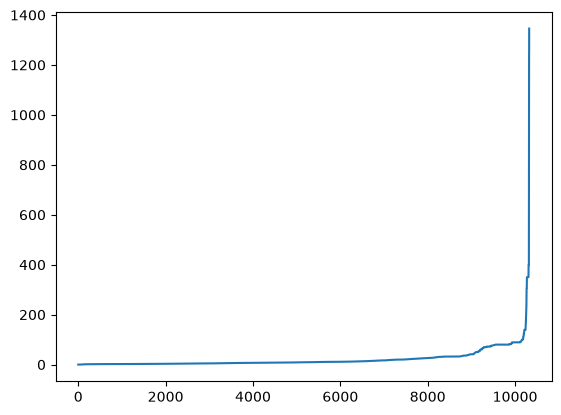

In [11]:
plt.plot(np.sort((data['line item value'] / data['line item quantity']).to_numpy()))
plt.show()

In [12]:
bleuh = []

for idx in range(len(data['weight (kilograms)'])):
    bleuh.append(data['weight (kilograms)'][idx][0] == "S")

data['weight (kilograms)'][bleuh]

8          See ASN-93 (ID#:1281)
88        See ASN-3562 (ID#:960)
96       See ASN-3675 (ID#:1046)
142         See ASN-242 (ID#:64)
143         See ASN-242 (ID#:64)
                  ...           
10314    See DN-4274 (ID#:84472)
10317    See DN-4282 (ID#:83919)
10318    See DN-4307 (ID#:83920)
10319    See DN-4307 (ID#:83920)
10320    See DN-4313 (ID#:83921)
Name: weight (kilograms), Length: 2445, dtype: str

In [13]:
data[data['id'] == 44]

,id,project code,pq #,po / so #,asn/dn #,country,managed by,fulfill via,vendor inco term,shipment mode,pq first sent to client date,po sent to vendor date,scheduled delivery date,delivered to client date,delivery recorded date,product group,sub classification,vendor,item description,molecule/test type,brand,dosage,dosage form,unit of measure (per pack),line item quantity,line item value,pack price,unit price,manufacturing site,first line designation,weight (kilograms),freight cost (usd),line item insurance (usd)
6,44,110-ZM-T01,Pre-PQ Process,SCMS-139,ASN-130,Zambia,PMO - US,Direct Drop,DDU,Air,Pre-PQ Process,Date Not Captured,8-Jan-07,8-Jan-07,8-Jan-07,ARV,Pediatric,MERCK SHARP & DOHME IDEA GMBH (FORMALLY MERCK SHARP & DOHME B.V.),"Efavirenz 200mg [Stocrin/Sustiva], capsule, 90 Caps",Efavirenz,Stocrin/Sustiva,200mg,Capsule,90,135,4374.0,32.4,0.36,MSD South Granville Australia,True,328,Freight Included in Commodity Cost,NaN


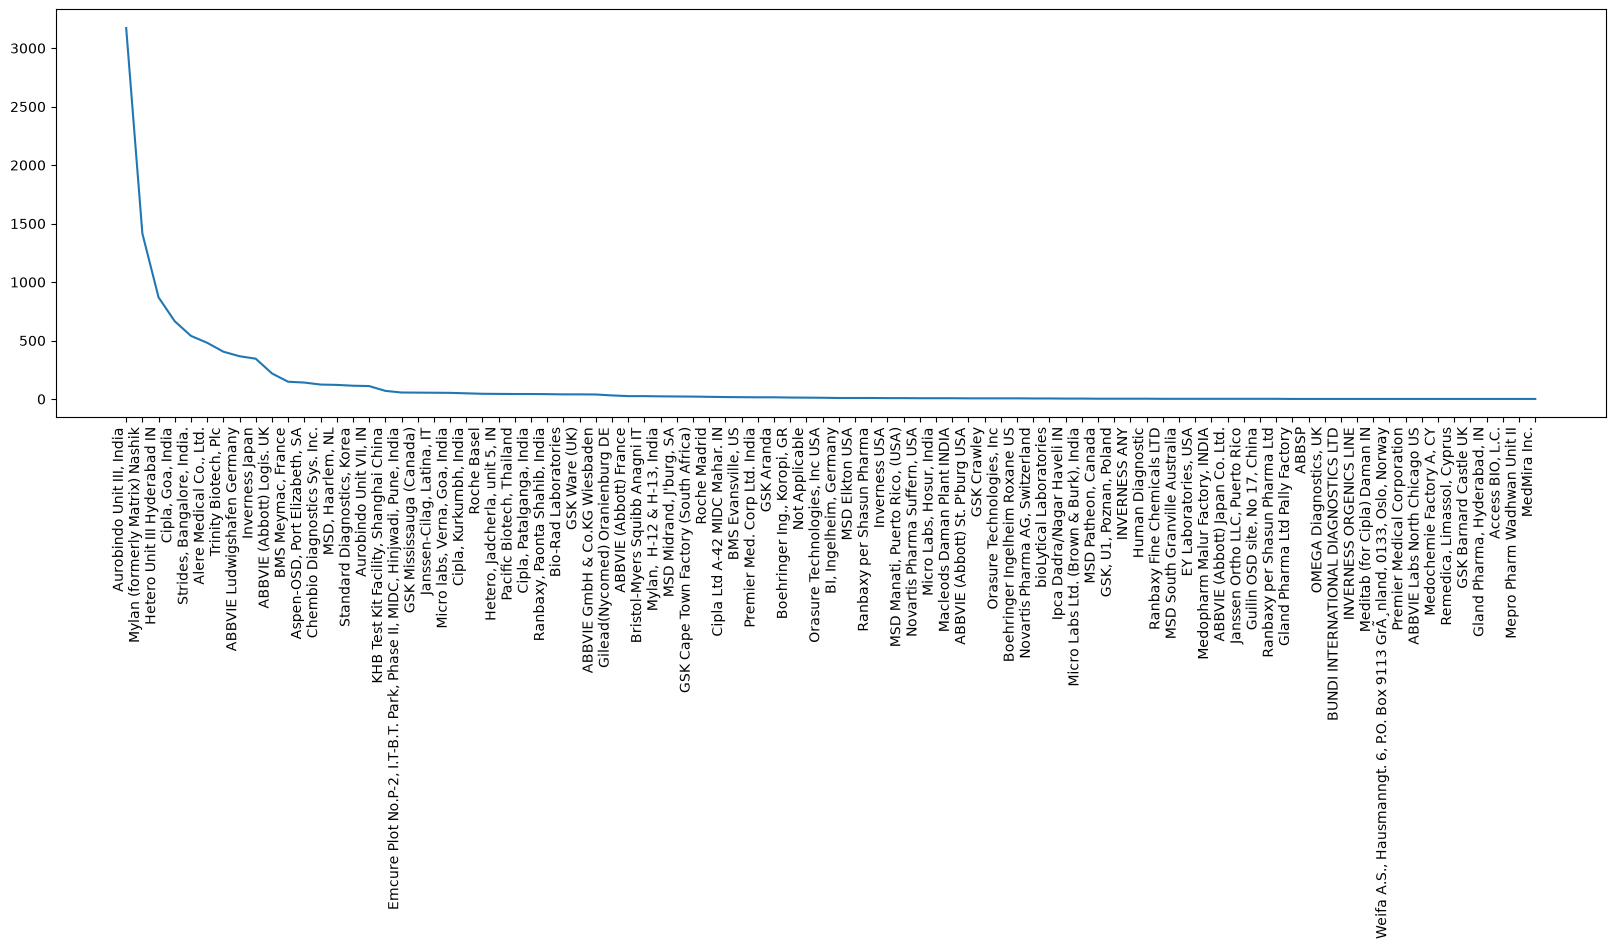

In [14]:
fig, ax = plt.subplots(figsize=(20, 6))
ax.plot(data['manufacturing site'].value_counts())
fig.autofmt_xdate(rotation=90)

In [15]:
data['manufacturing site'].value_counts().to_dict()

{'Aurobindo Unit III, India': 3172,
 'Mylan (formerly Matrix) Nashik': 1415,
 'Hetero Unit III Hyderabad IN': 869,
 'Cipla, Goa, India': 665,
 'Strides, Bangalore, India.': 540,
 'Alere Medical Co., Ltd.': 481,
 'Trinity Biotech, Plc': 405,
 'ABBVIE Ludwigshafen Germany': 366,
 'Inverness Japan': 345,
 'ABBVIE (Abbott) Logis. UK': 219,
 'BMS Meymac, France': 148,
 'Aspen-OSD, Port Elizabeth, SA': 141,
 'Chembio Diagnostics Sys. Inc.': 124,
 'MSD, Haarlem, NL': 121,
 'Standard Diagnostics, Korea': 114,
 'Aurobindo Unit VII, IN': 111,
 'KHB Test Kit Facility, Shanghai China': 70,
 'Emcure Plot No.P-2, I.T-B.T. Park, Phase II, MIDC, Hinjwadi, Pune, India': 56,
 'GSK Mississauga (Canada)': 55,
 'Janssen-Cilag, Latina, IT': 54,
 'Micro labs, Verna, Goa, India': 53,
 'Cipla, Kurkumbh, India': 49,
 'Roche Basel': 45,
 'Hetero, Jadcherla, unit 5, IN': 44,
 'Pacific Biotech, Thailand': 43,
 'Cipla, Patalganga, India': 43,
 'Ranbaxy, Paonta Shahib, India': 42,
 'Bio-Rad Laboratories': 40,
 'GSK 

# Code to Impute Data in weight which has references to different rows in data

In [16]:
copy = pd.read_csv('/Users/alphin/Documents/Semester 5/DA Project/copy.csv')

In [17]:
for idx in range(len(copy['weight (kilograms)'])):
    if copy['weight (kilograms)'][idx][0] == "S":
        text = copy['weight (kilograms)'][idx].split()
        asn_dn, id = text[1], text[2].strip("()").split(":")[1]

        weight = copy[(copy['id'] == int(id)) & (copy['asn/dn #'] == asn_dn)]['weight (kilograms)'].values[0]
        copy.loc[idx, 'weight (kilograms)'] = weight
        

# hehe

In [18]:
copy[copy['weight (kilograms)'] == 'Weight Captured Separately'].describe(include="all")

,id,project code,pq #,po / so #,asn/dn #,country,managed by,fulfill via,vendor inco term,shipment mode,pq first sent to client date,po sent to vendor date,scheduled delivery date,delivered to client date,delivery recorded date,product group,sub classification,vendor,item description,molecule/test type,brand,dosage,dosage form,unit of measure (per pack),line item quantity,line item value,pack price,unit price,manufacturing site,first line designation,weight (kilograms),freight cost (usd),line item insurance (usd)
count,1633.000000,1633,1633,1633,1633,1633,1633,1633,1633,1586,1633,1633,1633,1633,1633,1633,1633,1633,1633,1633,1633,1441,1633,1633.000000,1633.000000,1.633000e+03,1633.000000,1633.000000,1633,1633,1633,1633,1605.000000
unique,NaN,74,187,562,681,37,3,2,8,4,170,229,410,427,420,3,5,51,125,55,40,42,15,NaN,NaN,NaN,NaN,NaN,59,2,1,90,NaN
top,NaN,116-ZA-T30,Pre-PQ Process,SCMS-199289,ASN-19166,South Africa,PMO - US,Direct Drop,DDP,Truck,Pre-PQ Process,Date Not Captured,29-Aug-14,29-Aug-14,29-Aug-14,ARV,Adult,S. BUYS WHOLESALER,"Efavirenz 600mg, tablets, 30 Tabs",Efavirenz,Generic,300mg,Tablet,NaN,NaN,NaN,NaN,NaN,"Aurobindo Unit III, India",False,Weight Captured Separately,Freight Included in Commodity Cost,NaN
freq,NaN,758,469,67,54,1118,1575,1454,1140,990,449,239,67,67,67,1441,982,715,102,218,897,205,601,NaN,NaN,NaN,NaN,NaN,570,975,1633,1246,NaN
mean,38738.037967,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.733619,4879.222290,4.468903e+04,27.651225,0.599810,NaN,NaN,NaN,NaN,65.933371
std,27489.904766,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,77.107534,24180.117643,1.893124e+05,60.257314,2.019334,NaN,NaN,NaN,NaN,250.625252
min,62.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,1.000000,0.000000e+00,0.000000,0.000000,NaN,NaN,NaN,NaN,0.000000
25%,10821.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.000000,23.000000,3.244000e+02,6.650000,0.100000,NaN,NaN,NaN,NaN,0.380000
50%,37416.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60.000000,132.000000,2.163700e+03,16.820000,0.260000,NaN,NaN,NaN,NaN,2.920000
75%,62227.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.000000,1202.000000,1.500150e+04,28.500000,0.640000,NaN,NaN,NaN,NaN,23.050000


In [19]:
copy[copy['shipment mode'].isna()].describe(include="all")

,id,project code,pq #,po / so #,asn/dn #,country,managed by,fulfill via,vendor inco term,shipment mode,pq first sent to client date,po sent to vendor date,scheduled delivery date,delivered to client date,delivery recorded date,product group,sub classification,vendor,item description,molecule/test type,brand,dosage,dosage form,unit of measure (per pack),line item quantity,line item value,pack price,unit price,manufacturing site,first line designation,weight (kilograms),freight cost (usd),line item insurance (usd)
count,360.000000,360,360,360,360,360,360,360,360,0,360,360,360,360,360,360,360,360,360,360,360,309,360,360.000000,360.000000,3.600000e+02,360.000000,360.000000,360,360,360,360,254.000000
unique,NaN,15,1,220,226,12,1,2,5,0,1,8,127,130,129,3,5,7,68,35,28,30,11,NaN,NaN,NaN,NaN,NaN,36,2,204,261,NaN
top,NaN,110-ZM-T01,Pre-PQ Process,SCMS-16600,ASN-1520,Côte d'Ivoire,PMO - US,From RDC,N/A - From RDC,NaN,Pre-PQ Process,N/A - From RDC,21-Jan-08,4-Jan-08,4-Jan-08,ARV,Adult,SCMS from RDC,"Efavirenz 600mg, tablets, 30 Tabs",Efavirenz,Generic,600mg,Tablet,NaN,NaN,NaN,NaN,NaN,"Aurobindo Unit III, India",True,Weight Captured Separately,Freight Included in Commodity Cost,NaN
freq,NaN,99,360,18,16,113,360,312,312,NaN,360,312,20,16,16,309,239,312,42,62,213,44,126,NaN,NaN,NaN,NaN,NaN,141,226,47,49,NaN
mean,10683.311111,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,93.633333,10571.941667,1.121277e+05,26.780667,1.204667,NaN,NaN,NaN,NaN,196.738898
std,2571.053752,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,80.095236,18499.743518,1.983279e+05,42.496382,12.740643,NaN,NaN,NaN,NaN,346.458321
min,69.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,2.000000,1.520000e+00,0.010000,0.000000,NaN,NaN,NaN,NaN,0.000000
25%,10812.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.000000,484.250000,6.380000e+03,6.722500,0.100000,NaN,NaN,NaN,NaN,8.200000
50%,11373.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60.000000,1956.500000,3.144431e+04,16.125000,0.180000,NaN,NaN,NaN,NaN,46.220000
75%,12051.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.000000,10000.000000,1.205830e+05,35.275000,0.540000,NaN,NaN,NaN,NaN,209.855000


In [20]:
copy[copy['shipment mode'].isna() & copy['line item insurance (usd)'].isna()]

,id,project code,pq #,po / so #,asn/dn #,country,managed by,fulfill via,vendor inco term,shipment mode,pq first sent to client date,po sent to vendor date,scheduled delivery date,delivered to client date,delivery recorded date,product group,sub classification,vendor,item description,molecule/test type,brand,dosage,dosage form,unit of measure (per pack),line item quantity,line item value,pack price,unit price,manufacturing site,first line designation,weight (kilograms),freight cost (usd),line item insurance (usd)
779,7926,102-NG-T01,Pre-PQ Process,SCMS-33,ASN-19,Nigeria,PMO - US,Direct Drop,DDU,NaN,Pre-PQ Process,Date Not Captured,21-Jul-06,21-Jul-06,21-Jul-06,HRDT,HIV test,ACCOUN NIGERIA LIMITED,"HIV 1/2, Determine Complete HIV Kit, 100 Tests","HIV 1/2, Determine Complete HIV Kit",Determine,NaN,Test kit,100,500,60000.00,120.00,1.20,ABBVIE (Abbott) Japan Co. Ltd.,True,Weight Captured Separately,Freight Included in Commodity Cost,NaN
999,11100,110-ZM-T01,Pre-PQ Process,SO-310,DN-122,Zambia,PMO - US,From RDC,N/A - From RDC,NaN,Pre-PQ Process,N/A - From RDC,4-May-07,4-May-07,4-May-07,ARV,Adult,SCMS from RDC,"Abacavir 300mg, tablets, 60 Tabs",Abacavir,Generic,300mg,Tablet,60,1000,35800.00,35.80,0.60,"Aurobindo Unit III, India",True,4436,18375.7,NaN
1024,10534,110-ZM-T01,Pre-PQ Process,SO-220,DN-4,Zambia,PMO - US,From RDC,N/A - From RDC,NaN,Pre-PQ Process,N/A - From RDC,2-Feb-07,2-Feb-07,2-Feb-07,ARV,Adult,SCMS from RDC,"Nelfinavir (as mesilate) 250mg [Viracept], tablets, 270 Tabs",Nelfinavir (as mesilate),Viracept,250mg,Tablet,270,228,17948.16,78.72,0.29,Roche Madrid,True,60,1218.91,NaN
1028,10539,112-NG-T01,Pre-PQ Process,SO-328,DN-22,Nigeria,PMO - US,From RDC,N/A - From RDC,NaN,Pre-PQ Process,N/A - From RDC,22-Feb-07,22-Feb-07,22-Feb-07,ARV,Adult,SCMS from RDC,"Lamivudine/Zidovudine+Nevirapine 150/300+200mg, tablets, co-blister, 60+60 Tabs",Lamivudine/Zidovudine+Nevirapine,Generic,150/300+200mg,Tablet - FDC + co-blister,120,5151,105595.50,20.50,0.17,"Aspen-OSD, Port Elizabeth, SA",True,667,2921,NaN
1029,10540,100-CI-T01,Pre-PQ Process,SO-283,DN-16,Côte d'Ivoire,PMO - US,From RDC,N/A - From RDC,NaN,Pre-PQ Process,N/A - From RDC,22-Feb-07,22-Feb-07,22-Feb-07,ARV,Adult,SCMS from RDC,"Lamivudine/Zidovudine 150/300mg, tablets, 60 Tabs",Lamivudine/Zidovudine,Generic,150/300mg,Tablet - FDC,60,2230,22857.50,10.25,0.17,"Aurobindo Unit III, India",True,909,2804,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2495,12649,100-CI-T01,Pre-PQ Process,SO-432,DN-82,Côte d'Ivoire,PMO - US,From RDC,N/A - From RDC,NaN,Pre-PQ Process,N/A - From RDC,30-Apr-07,30-Apr-07,30-Apr-07,ARV,Adult,SCMS from RDC,"Lamivudine/Nevirapine/Stavudine 150/200/30mg, tablets, 60 Tabs",Lamivudine/Nevirapine/Stavudine,Generic,150/200/30mg,Tablet - FDC,60,9000,67500.00,7.50,0.12,"Cipla, Goa, India",True,974,3166,NaN
2497,12656,104-CI-T01,Pre-PQ Process,SO-517,DN-160,Côte d'Ivoire,PMO - US,From RDC,N/A - From RDC,NaN,Pre-PQ Process,N/A - From RDC,15-Jun-07,15-Jun-07,15-Jun-07,ARV,Adult,SCMS from RDC,"Nelfinavir (as mesilate) 250mg [Viracept], tablets, 270 Tabs",Nelfinavir (as mesilate),Viracept,250mg,Tablet,270,460,37453.20,81.42,0.30,Roche Madrid,False,1313,See DN-160 (ID#:11397),NaN
2499,12659,104-CI-T01,Pre-PQ Process,SO-518,DN-149,Côte d'Ivoire,PMO - US,From RDC,N/A - From RDC,NaN,Pre-PQ Process,N/A - From RDC,18-May-07,18-May-07,18-May-07,HRDT,HIV test,SCMS from RDC,"#108853** HIV, Genie II HIV-1/HIV-2 Kit, 40 Tests","HIV, Genie II HIV-1/HIV-2 Kit",Genie,NaN,Test kit,40,160,12160.00,76.00,1.90,Bio-Rad Laboratories,True,173,1754,NaN
2500,12661,104-CI-T01,Pre-PQ Process,SO-640,DN-173,Côte d'Ivoire,PMO - US,From RDC,N/A - From RDC,NaN,Pre-PQ Process,N/A - From RDC,21-Jun-07,21-Jun-07,21-Jun-07,ARV,Adult,SCMS from RDC,"Lamivudine/Zidovudine 150/300mg, tablets, 60 Tabs",Lamivudine/Zidovudine,Generic,150/300mg,Tablet - FDC,60,35074,374590.32,10.68,0.18,"Aurobindo Unit III, India",True,

In [21]:
temp = copy['country'].unique()

In [22]:
all(len(data['scheduled delivery date'][idx]) == 8 for idx in range(data.shape[0]))

False

In [23]:
from datetime import datetime

scheduled_time = []
delivery_time = []

for idx in range(data.shape[0]):
    date, month, time = data['scheduled delivery date'][idx].split("-")
    mMap = {
        'Jan' : 1,
        'Feb' : 2,
        'Mar' : 3,
        'Apr' : 4,
        'May' : 5,
        'Jun' : 6,
        'Jul' : 7,
        'Aug' : 8,
        'Sep' : 9,
        'Oct' : 10,
        'Nov' : 11,
        'Dec' : 12
    }

    code = f"{date}-{mMap[month]}-{time}"
    dt = datetime.strptime(code, "%d-%m-%y" if len(code.split('-')[-1]) == 2 else "%d-%m-%Y")
    scheduled_time.append(int(dt.timestamp()))

    date, month, time = data['delivered to client date'][idx].split("-")
    code = f"{date}-{mMap[month]}-{time}"
    dt = datetime.strptime(code, "%d-%m-%y" if len(code.split('-')[-1]) == 2 else "%d-%m-%Y")
    delivery_time.append(int(dt.timestamp()))

scheduled_time = np.array(scheduled_time)
delivery_time = np.array(delivery_time)

diff = delivery_time - scheduled_time

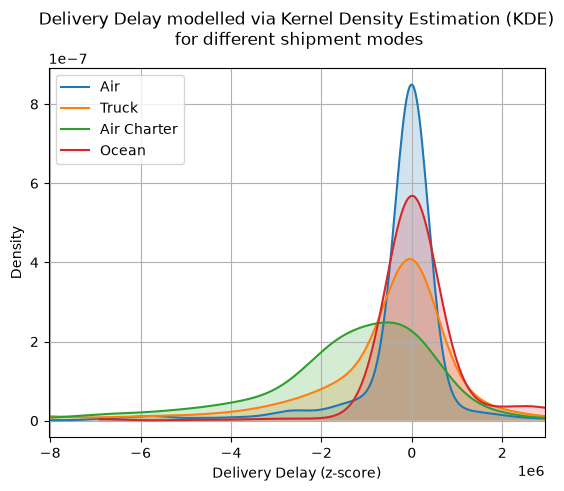

In [24]:
modes = data['shipment mode'].unique().dropna()
masks = [data['shipment mode'] == mode for mode in modes]

for idx in range(len(modes)):
    tdata = np.sort(diff[masks[idx]])
    kde = gaussian_kde(tdata)

    # Generate points for plotting
    x = np.linspace(tdata.min(), tdata.max(), 1000)
    y = kde(x)

    # Plot
    plt.plot(x, y, label=f"{modes[idx]}")
    plt.fill_between(x, y, alpha=0.2)


plt.xlabel("Value")
plt.ylabel("Density")
plt.xlim(np.percentile(diff, 2), np.percentile(diff, 98))
plt.title("Delivery Delay modelled via Kernel Density Estimation (KDE)\n for different shipment modes")
plt.xlabel("Delivery Delay (z-score)")
plt.ylabel("Density")
plt.legend()
plt.grid()
plt.show()

In [25]:
country_map = [data['country'] == country for country in data['country'].unique()]
times = {}

for country in data['country'].unique():
    tdata = np.sort(diff[data['country'] == country])
    times[country] = tdata.mean()

pos_time, neg_time = [country for country in data['country'].unique() if times[country] > 0], [country for country in data['country'].unique() if times[country] <= 0]

/Users/alphin/Documents/Semester 5/DA Project/.env/lib/python3.14/site-packages/geopandas/plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)


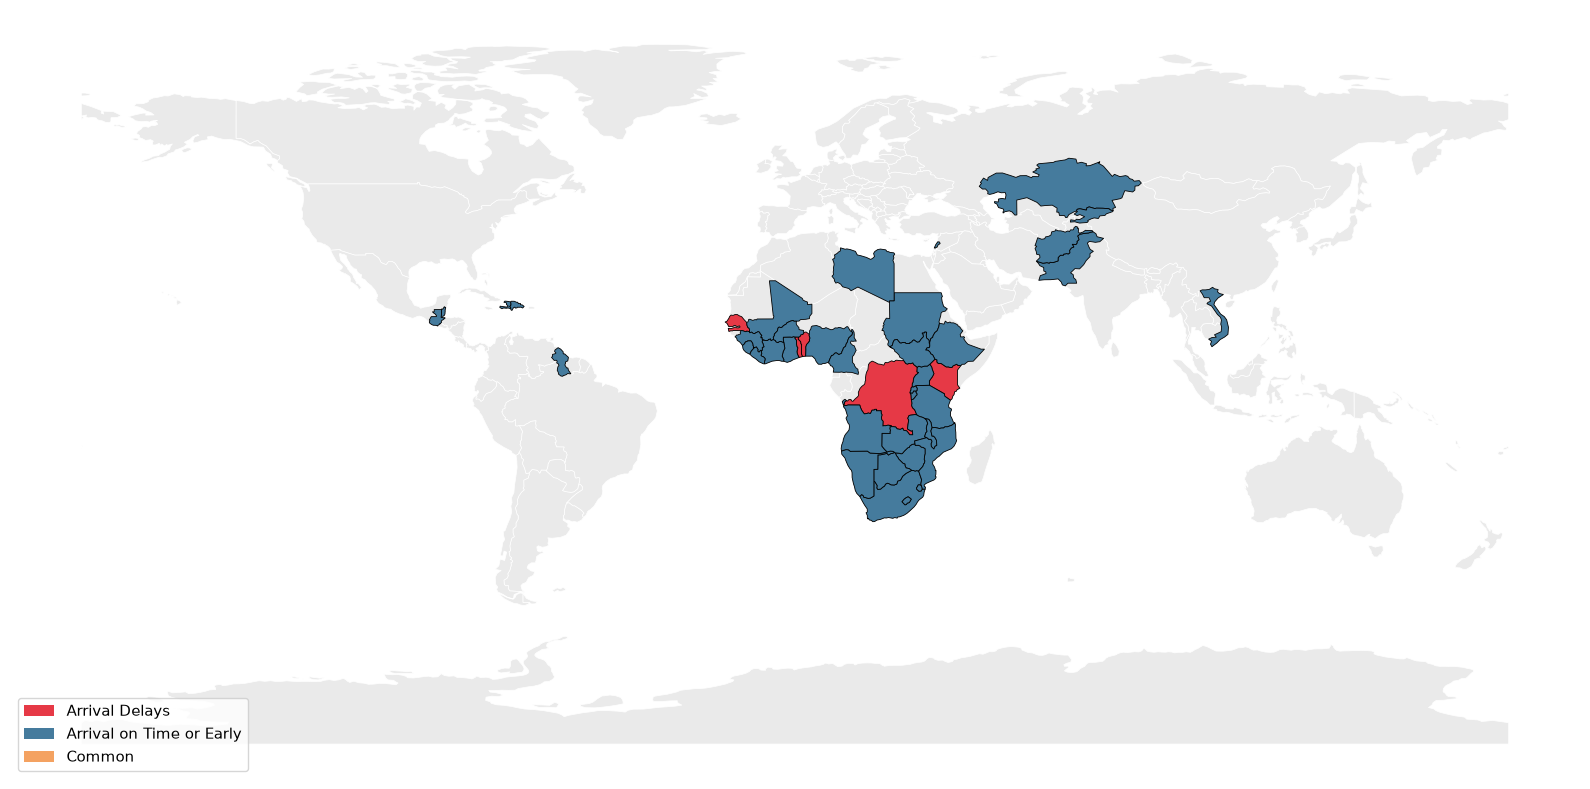

In [26]:
double_highlight_countries(
    countries_1 = pos_time + ['Democratic Republic of the Congo'],
    countries_2 = neg_time + ['United Republic of Tanzania', 'eSwatini', 'Ivory Coast'],
    label_1 = "Arrival Delays",
    label_2 = "Arrival on Time or Early",
    color_1 = "#E63946",
    color_2 = "#457B9D",
    color_common = "#F4A261"
)

In [27]:
import json

with open("manufacturing_site.json", "r") as f:
    manufacturing_sites = json.load(f)

man_countries = [manufacturing_sites[data['manufacturing site'][idx]] for idx in range(data.shape[0]) if data['manufacturing site'][idx] in manufacturing_sites]
delay_times = {country : [0,0,0] for country in set(manufacturing_sites.values())}

for idx in range(data.shape[0]):
    if data['manufacturing site'][idx] in manufacturing_sites:
        country = manufacturing_sites[data['manufacturing site'][idx]]
        delay_times[country][0] += 1
        delay_times[country][1] += diff[idx]

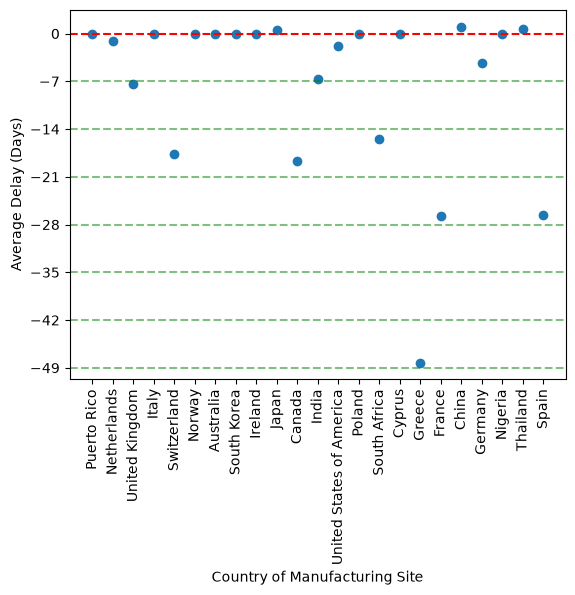

In [28]:
for country in delay_times:
    if delay_times[country][0] > 0:
        delay_times[country][2] = delay_times[country][1] / delay_times[country][0]

plt.scatter(delay_times.keys(), [delay_times[country][2] / 86400 for country in delay_times])
plt.axhline(y=0, color='r', linestyle='--')
for wk in range(-7, -50 , -7):
    plt.axhline(y=wk, color='g', linestyle='--', alpha=0.5)
plt.xlabel("Country of Manufacturing Site")
plt.ylabel("Average Delay (Days)")
plt.xticks(rotation=90)
plt.yticks(np.arange(-49, 7, 7))
plt.show()

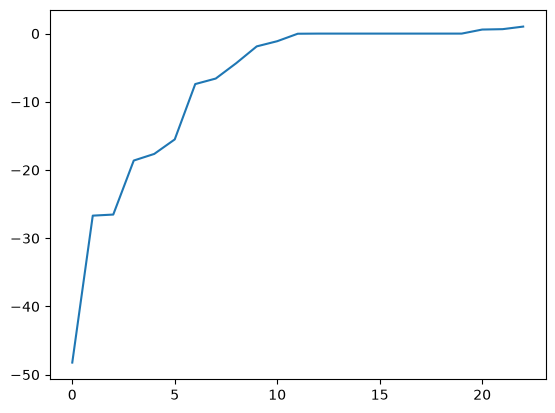

In [29]:
plt.plot(np.sort([delay_times[country][2] / 86400 for country in delay_times]))

In [30]:
data

,id,project code,pq #,po / so #,asn/dn #,country,managed by,fulfill via,vendor inco term,shipment mode,pq first sent to client date,po sent to vendor date,scheduled delivery date,delivered to client date,delivery recorded date,product group,sub classification,vendor,item description,molecule/test type,brand,dosage,dosage form,unit of measure (per pack),line item quantity,line item value,pack price,unit price,manufacturing site,first line designation,weight (kilograms),freight cost (usd),line item insurance (usd)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,2-Jun-06,2-Jun-06,2-Jun-06,HRDT,HIV test,RANBAXY Fine Chemicals LTD.,"HIV, Reveal G3 Rapid HIV-1 Antibody Test, 30 Tests","HIV, Reveal G3 Rapid HIV-1 Antibody Test",Reveal,NaN,Test kit,30,19,551.00,29.00,0.97,Ranbaxy Fine Chemicals LTD,True,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,14-Nov-06,14-Nov-06,14-Nov-06,ARV,Pediatric,Aurobindo Pharma Limited,"Nevirapine 10mg/ml, oral suspension, Bottle, 240 ml",Nevirapine,Generic,10mg/ml,Oral suspension,240,1000,6200.00,6.20,0.03,"Aurobindo Unit III, India",True,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,Pre-PQ Process,Date Not Captured,27-Aug-06,27-Aug-06,27-Aug-06,HRDT,HIV test,Abbott GmbH & Co. KG,"HIV 1/2, Determine Complete HIV Kit, 100 Tests","HIV 1/2, Determine Complete HIV Kit",Determine,NaN,Test kit,100,500,40000.00,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,True,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,1-Sep-06,1-Sep-06,1-Sep-06,ARV,Adult,SUN PHARMACEUTICAL INDUSTRIES LTD (RANBAXY LABORATORIES LIMITED),"Lamivudine 150mg, tablets, 60 Tabs",Lamivudine,Generic,150mg,Tablet,60,31920,127360.80,3.99,0.07,"Ranbaxy, Paonta Shahib, India",True,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,11-Aug-06,11-Aug-06,11-Aug-06,ARV,Adult,Aurobindo Pharma Limited,"Stavudine 30mg, capsules, 60 Caps",Stavudine,Generic,30mg,Capsule,60,38000,121600.00,3.20,0.05,"Aurobindo Unit III, India",True,7590,45450.08,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10319,86818,103-ZW-T30,FPQ-15197,SO-50020,DN-4307,Zimbabwe,PMO - US,From RDC,N/A - From RDC,Truck,10/16/2014,N/A - From RDC,31-Jul-15,15-Jul-15,20-Jul-15,ARV,Pediatric,SCMS from RDC,"Lamivudine/Nevirapine/Zidovudine 30/50/60mg, dispersible tablets, 60 Tabs",Lamivudine/Nevirapine/Zidovudine,Generic,30/50/60mg,Chewable/dispersible tablet - FDC,60,166571,599655.60,3.60,0.06,"Mylan, H-12 & H-13, India",False,See DN-4307 (ID#:83920),See DN-4307 (ID#:83920),705.79
10320,86819,104-CI-T30,FPQ-15259,SO-50102,DN-4313,Côte d'Ivoire,PMO - US,From RDC,N/A - From RDC,Truck,10/24/2014,N/A - From RDC,31-Jul-15,6-Aug-15,7-Aug-15,ARV,Adult,SCMS from RDC,"Lamivudine/Zidovudine 150/300mg, tablets, 60 Tabs",Lamivudine/Zidovudine,Generic,150/300mg,Tablet - FDC,60,21072,137389.44,6.52,0.11,Hetero Unit III Hyderabad IN,False,See DN-4313 (ID#:83921),See DN-4313 (ID#:83921),161.71
10321,86821,110-ZM-T30,FPQ-14784,SO-49600,DN-4316,Zambia,PMO - US,From RDC,N/A - From RDC,Truck,8/12/2014,N/A - From RDC,31-Aug-15,25-Aug-15,3-Sep-15,ARV,Adult,SCMS from RDC,"Efavirenz/Lamivudine/Tenofovir Disoproxil Fumarate 600/300/300mg, tablets, 30 Tabs",Efavirenz/Lamivudine/Tenofovir Disoproxil Fumarate,Generic,600/300/300mg,Tablet - FDC,30,514526,5140114.74,9.99,0.33,Cipla Ltd A-42 MIDC Mahar. IN,False,Weight Captured Separately,Freight Included in Commodity Cost,5284.04
10322,86822,200-ZW-T30,FPQ-16523,SO-51680,DN-4334,Zimbabwe,PMO - US,From RDC,N/A - From RDC,Truck,7/1/2015,N/A - From RDC,9-Sep-15,4-Aug-15,11-Aug-15,ARV,Adult,SCMS from RDC,"Lamivudine/Zidovu

In [31]:
res = data.groupby('vendor')['line item value'].sum()
ordered_res = res.groupby('vendor').count()

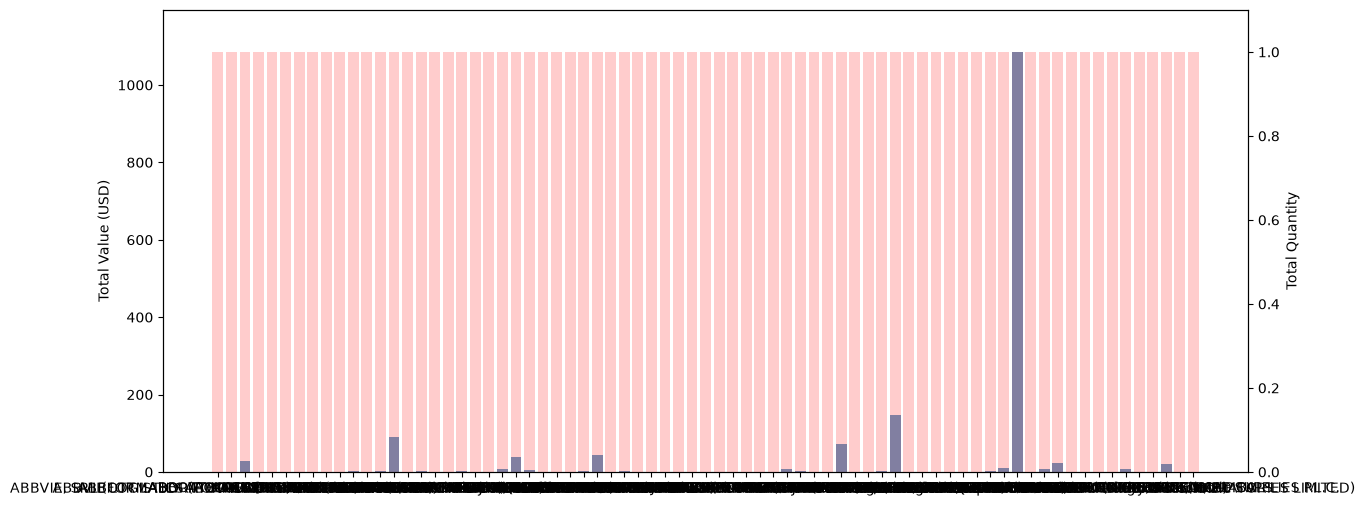

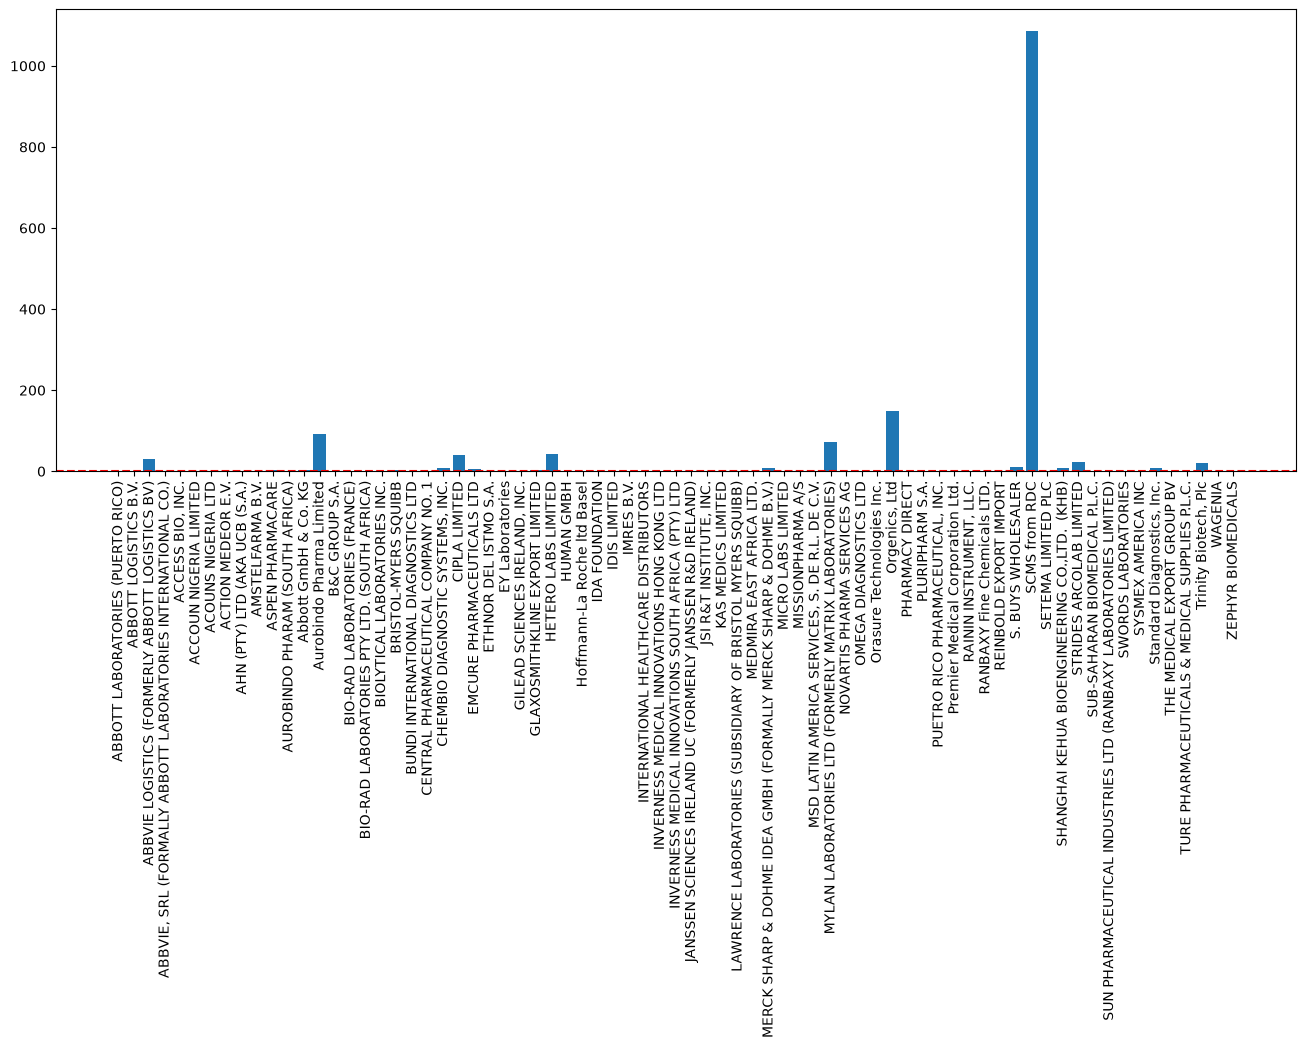

In [32]:
fig, ax1 = plt.subplots(figsize=(14, 6))
ax2 = ax1.twinx()

ax1.bar(res.index, res.values / 1e6, alpha=0.7)
ax2.bar(ordered_res.index, ordered_res.values, color='red', alpha = 0.2)

# Independent scaling
ax1.set_ylim(0, max(res.values / 1e6) * 1.1)
ax2.set_ylim(0, max(ordered_res.values) * 1.1)

ax1.set_ylabel('Total Value (USD)')
ax2.set_ylabel('Total Quantity')

plt.show()







plt.figure(figsize=(16, 6))
plt.bar(res.index, res.values / 1e6)
plt.xticks(rotation=90)
plt.axhline(y=0, color='r', linestyle='--')
plt.show()

In [33]:
data

,id,project code,pq #,po / so #,asn/dn #,country,managed by,fulfill via,vendor inco term,shipment mode,pq first sent to client date,po sent to vendor date,scheduled delivery date,delivered to client date,delivery recorded date,product group,sub classification,vendor,item description,molecule/test type,brand,dosage,dosage form,unit of measure (per pack),line item quantity,line item value,pack price,unit price,manufacturing site,first line designation,weight (kilograms),freight cost (usd),line item insurance (usd)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,2-Jun-06,2-Jun-06,2-Jun-06,HRDT,HIV test,RANBAXY Fine Chemicals LTD.,"HIV, Reveal G3 Rapid HIV-1 Antibody Test, 30 Tests","HIV, Reveal G3 Rapid HIV-1 Antibody Test",Reveal,NaN,Test kit,30,19,551.00,29.00,0.97,Ranbaxy Fine Chemicals LTD,True,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,14-Nov-06,14-Nov-06,14-Nov-06,ARV,Pediatric,Aurobindo Pharma Limited,"Nevirapine 10mg/ml, oral suspension, Bottle, 240 ml",Nevirapine,Generic,10mg/ml,Oral suspension,240,1000,6200.00,6.20,0.03,"Aurobindo Unit III, India",True,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,Pre-PQ Process,Date Not Captured,27-Aug-06,27-Aug-06,27-Aug-06,HRDT,HIV test,Abbott GmbH & Co. KG,"HIV 1/2, Determine Complete HIV Kit, 100 Tests","HIV 1/2, Determine Complete HIV Kit",Determine,NaN,Test kit,100,500,40000.00,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,True,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,1-Sep-06,1-Sep-06,1-Sep-06,ARV,Adult,SUN PHARMACEUTICAL INDUSTRIES LTD (RANBAXY LABORATORIES LIMITED),"Lamivudine 150mg, tablets, 60 Tabs",Lamivudine,Generic,150mg,Tablet,60,31920,127360.80,3.99,0.07,"Ranbaxy, Paonta Shahib, India",True,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,11-Aug-06,11-Aug-06,11-Aug-06,ARV,Adult,Aurobindo Pharma Limited,"Stavudine 30mg, capsules, 60 Caps",Stavudine,Generic,30mg,Capsule,60,38000,121600.00,3.20,0.05,"Aurobindo Unit III, India",True,7590,45450.08,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10319,86818,103-ZW-T30,FPQ-15197,SO-50020,DN-4307,Zimbabwe,PMO - US,From RDC,N/A - From RDC,Truck,10/16/2014,N/A - From RDC,31-Jul-15,15-Jul-15,20-Jul-15,ARV,Pediatric,SCMS from RDC,"Lamivudine/Nevirapine/Zidovudine 30/50/60mg, dispersible tablets, 60 Tabs",Lamivudine/Nevirapine/Zidovudine,Generic,30/50/60mg,Chewable/dispersible tablet - FDC,60,166571,599655.60,3.60,0.06,"Mylan, H-12 & H-13, India",False,See DN-4307 (ID#:83920),See DN-4307 (ID#:83920),705.79
10320,86819,104-CI-T30,FPQ-15259,SO-50102,DN-4313,Côte d'Ivoire,PMO - US,From RDC,N/A - From RDC,Truck,10/24/2014,N/A - From RDC,31-Jul-15,6-Aug-15,7-Aug-15,ARV,Adult,SCMS from RDC,"Lamivudine/Zidovudine 150/300mg, tablets, 60 Tabs",Lamivudine/Zidovudine,Generic,150/300mg,Tablet - FDC,60,21072,137389.44,6.52,0.11,Hetero Unit III Hyderabad IN,False,See DN-4313 (ID#:83921),See DN-4313 (ID#:83921),161.71
10321,86821,110-ZM-T30,FPQ-14784,SO-49600,DN-4316,Zambia,PMO - US,From RDC,N/A - From RDC,Truck,8/12/2014,N/A - From RDC,31-Aug-15,25-Aug-15,3-Sep-15,ARV,Adult,SCMS from RDC,"Efavirenz/Lamivudine/Tenofovir Disoproxil Fumarate 600/300/300mg, tablets, 30 Tabs",Efavirenz/Lamivudine/Tenofovir Disoproxil Fumarate,Generic,600/300/300mg,Tablet - FDC,30,514526,5140114.74,9.99,0.33,Cipla Ltd A-42 MIDC Mahar. IN,False,Weight Captured Separately,Freight Included in Commodity Cost,5284.04
10322,86822,200-ZW-T30,FPQ-16523,SO-51680,DN-4334,Zimbabwe,PMO - US,From RDC,N/A - From RDC,Truck,7/1/2015,N/A - From RDC,9-Sep-15,4-Aug-15,11-Aug-15,ARV,Adult,SCMS from RDC,"Lamivudine/Zidovu

In [34]:
def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0  # Earth radius in km

    lat1, lon1, lat2, lon2 = np.radians(
        [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2)**2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2)**2
    )

    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

    return R * c

In [35]:
import pycountry

def country_to_iso3(name):
    if name == "Swaziland":
        name = "eSwatini"
    if name == "Congo, DRC":
        name = "Congo"
        
    if pd.isna(name):
        return None

    name = str(name).strip()

    # Try exact ISO name lookup
    try:
        return pycountry.countries.lookup(name).alpha_3
    except LookupError:
        return None

In [36]:
lat_lon_data = pd.read_csv('/Users/alphin/Documents/Semester 5/DA Project/countries.csv')
lat_lon_data['ISO3'] = lat_lon_data['COUNTRY'].apply(country_to_iso3)

In [37]:
man_map = json.load(open("manufacturing_site.json"))

In [38]:
cache = {}
delivery_distance = []

for idx in range(data.shape[0]):
    destination = country_to_iso3(data['country'][idx])
    source = country_to_iso3(man_map[data['manufacturing site'][idx]]) if data['manufacturing site'][idx] in man_map else None

    if source is None:
        print(f"Manufacturing site {data['manufacturing site'][idx]} not found in mapping.")
        delivery_distance.append(None)
        continue

    
    if destination in cache:
        dest_lat, dest_lon = cache[destination]
    else:
        dest_lat, dest_lon = lat_lon_data[lat_lon_data['ISO3'] == destination][['latitude', 'longitude']].values[0]
        cache[destination] = (dest_lat, dest_lon)

    if source in cache:
        src_lat, src_lon = cache[source]
    else:
        src_lat, src_lon = lat_lon_data[lat_lon_data['ISO3'] == source][['latitude', 'longitude']].values[0]
        cache[source] = (src_lat, src_lon)

    distance = haversine(src_lat, src_lon, dest_lat, dest_lon)
    delivery_distance.append(distance)

Manufacturing site Not Applicable not found in mapping.
Manufacturing site Not Applicable not found in mapping.
Manufacturing site Not Applicable not found in mapping.
Manufacturing site Not Applicable not found in mapping.
Manufacturing site Not Applicable not found in mapping.
Manufacturing site Not Applicable not found in mapping.
Manufacturing site Not Applicable not found in mapping.
Manufacturing site Not Applicable not found in mapping.
Manufacturing site Not Applicable not found in mapping.
Manufacturing site Not Applicable not found in mapping.
Manufacturing site Not Applicable not found in mapping.
Manufacturing site Not Applicable not found in mapping.


In [39]:
shipment_mode_ohe = pd.get_dummies(
    data["shipment mode"],
    prefix="Shipment Mode",
    dtype=int
)

clustering_data = pd.concat([
    pd.DataFrame({
        'delivery distance (km)': delivery_distance,
        'line item value (USD)': data['line item value'],
        'line item quantity': data['line item quantity'],
        'pack price (USD)': data['pack price'],
    }),
    shipment_mode_ohe
], axis=1)

print(clustering_data.head())

   delivery distance (km)  line item value (USD)  line item quantity  \
0             9343.288422                  551.0                  19   
1             2696.641317                 6200.0                1000   
2             5061.240546                40000.0                 500   
3             2696.641317               127360.8               31920   
4             2696.641317               121600.0               38000   

   pack price (USD)  Shipment Mode_Air  Shipment Mode_Air Charter  \
0             29.00                  1                          0   
1              6.20                  1                          0   
2             80.00                  1                          0   
3              3.99                  1                          0   
4              3.20                  1                          0   

   Shipment Mode_Ocean  Shipment Mode_Truck  
0                    0                    0  
1                    0                    0  
2             

In [40]:
clustering_data

,delivery distance (km),line item value (USD),line item quantity,pack price (USD),Shipment Mode_Air,Shipment Mode_Air Charter,Shipment Mode_Ocean,Shipment Mode_Truck
0,9343.288422,551.00,19,29.00,1,0,0,0
1,2696.641317,6200.00,1000,6.20,1,0,0,0
2,5061.240546,40000.00,500,80.00,1,0,0,0
3,2696.641317,127360.80,31920,3.99,1,0,0,0
4,2696.641317,121600.00,38000,3.20,1,0,0,0
...,...,...,...,...,...,...,...,...
10319,7313.252004,599655.60,166571,3.60,0,0,0,1
10320,9343.288422,137389.44,21072,6.52,0,0,0,1
10321,7099.818792,5140114.74,514526,9.99,0,0,0,1
10322,7313.252004,113871.80,17465,6.52,0,0,0,1


In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [42]:
X = clustering_data[['delivery distance (km)', 'line item value (USD)', 'line item quantity']]

# Remove rows with missing values
X = X.dropna()

# Convert everything to numeric
X = X.astype(float)

print(X.describe())

       delivery distance (km)  line item value (USD)  line item quantity
count            10312.000000           1.031200e+04        10312.000000
mean              8097.211251           1.578180e+05        18353.608514
std               2990.165472           3.454577e+05        40053.822584
min                  0.000000           0.000000e+00            1.000000
25%               6227.115185           4.323600e+03          413.750000
50%               7860.871146           3.051753e+04         3004.000000
75%               9343.288422           1.666309e+05        17100.750000
max              16336.549729           5.951990e+06       619999.000000


In [43]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [44]:
pca = PCA()

X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_

print("Explained variance:", explained_variance)
print("Cumulative variance:", np.cumsum(explained_variance))

Explained variance: [0.61763684 0.32929962 0.05306354]
Cumulative variance: [0.61763684 0.94693646 1.        ]


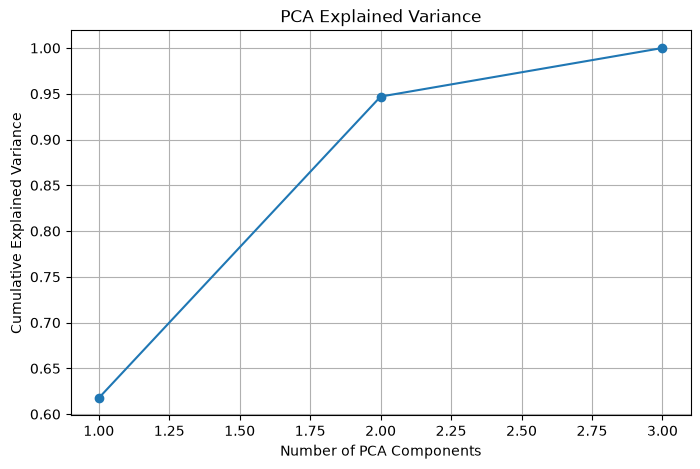

In [45]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    np.cumsum(explained_variance),
    marker='o'
)

plt.xlabel("Number of PCA Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")
plt.grid(True)
plt.show()

In [46]:
pca = PCA(n_components=0.95)

X_pca = pca.fit_transform(X_scaled)

print("Original dimensions:", X_scaled.shape[1])
print("PCA dimensions:", X_pca.shape[1])
print("Variance retained:", pca.explained_variance_ratio_.sum())

Original dimensions: 3
PCA dimensions: 3
Variance retained: 0.9999999999999999


In [47]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_pca)

    score = silhouette_score(X_pca, labels)
    silhouette_scores.append(score)

    print(f"k = {k}, silhouette score = {score:.4f}")

k = 2, silhouette score = 0.6676
k = 3, silhouette score = 0.5192
k = 4, silhouette score = 0.5337
k = 5, silhouette score = 0.4349
k = 6, silhouette score = 0.4569
k = 7, silhouette score = 0.4625
k = 8, silhouette score = 0.4426
k = 9, silhouette score = 0.4443
k = 10, silhouette score = 0.4451


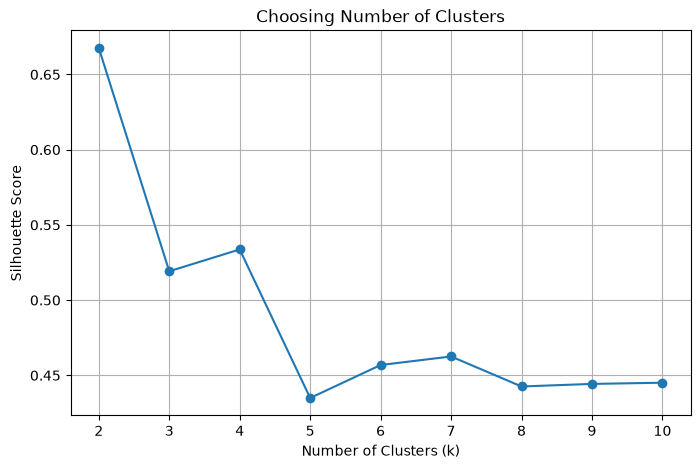

In [48]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Choosing Number of Clusters")
plt.grid(True)
plt.show()

In [49]:
best_k = range(2, 11)[np.argmax(silhouette_scores)]

print("Best k:", best_k)

Best k: 2


In [50]:
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_pca)

clustering_data.loc[X.index, "Cluster"] = clusters

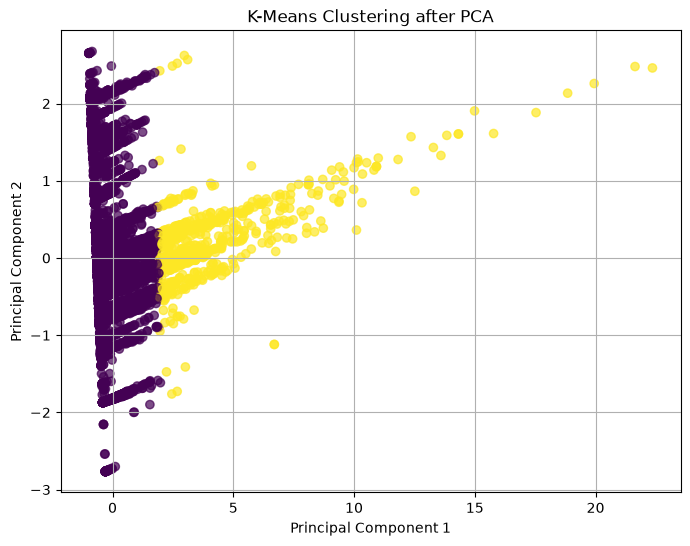

In [51]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering after PCA")
plt.grid(True)
plt.show()